# Notebook 2: Proxy model

**Role:** proxy team (Elton's model, chosen by the team). **Feeds:** `notebook3_hist_match.ipynb`.

A *proxy* is a fast learned copy of the reservoir simulator. It takes the 4 uncertainty parameters of a case and returns the whole production curve in milliseconds, so the history matching can try many thousands of parameter sets.

```
 4 parameters (+ 8 grid features) --> [ MLP, 5-seed ensemble ] --> 41 quarterly dates x (oil, gas, water)
```

This notebook reproduces Elton's setup exactly (`Elton Model/proxy_model.py`, `forecast_pipeline.py`). The model code lives in `src/proxy_lib.py` (a copy of his code with the paths changed), so that notebook 3 loads the same model.

| Section | What it does |
|---|---|
| 1 | Data: rates and cumulatives on the 41 shared quarterly dates; split 70 / 15 / 15 |
| 2 | Features: 4 parameters (`p4`), or 4 parameters + 8 grid features (`p4g8`); grid mapping for new parameter sets |
| 3 | Model: small MLP that learns each case's difference from the mean training curve |
| 4 | Hyper-parameter tuning: two-stage 5-fold CV search |
| 5 | **Rate proxy**: final 5-seed ensemble, baselines, metrics, figures |
| 6 | **Cumulative twin proxy**: same config on cumulative curves (this is the proxy the history matching uses) |
| 7 | Accuracy in history-matching units: error as % of the final observed cumulative; does the proxy rank cases like the simulator? |
| 8 | Export to `hist_match_input/` for notebook 3 |

**Data protocol (unchanged from Elton).** Train on cases 1-70. Hyper-parameters by 5-fold CV inside those 70. Validation cases 71-85 and test cases 86-100 are never fitted.

**What changed from Elton's scripts (improvised).**
* Paths: data from `data_after_engineering/`, outputs to `proxy_output/` and `hist_match_input/`.
* The checkpoint stores the parameter-to-grid-feature mapping (Elton's `GridMapper`), so notebook 3 uses the same mapping.
* Prediction builds the 5 networks once instead of on every call (identical numbers, ~13x faster for the MCMC).
* New section 7: accuracy in the units the history matching uses, and the proxy error passed to notebook 3.

In [1]:
import sys, json, time, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import spearmanr

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_after_engineering").exists())
sys.path.insert(0, str(ROOT / "src"))
import proxy_lib as pl

PROXY_DIR = ROOT / "proxy_output"            # models, metrics, figures of this notebook
FIG_DIR = PROXY_DIR / "figs"
HM_IN = ROOT / "hist_match_input"            # hand-over folder read by notebook 3
ELTON_OUT = ROOT / "Elton Model" / "proxy_outputs"   # Elton's own results, for comparison only
for d in (PROXY_DIR, FIG_DIR, HM_IN):
    d.mkdir(exist_ok=True)

RUN_TUNE = True        # False: skip the ~6 min search and use Elton's best_config.json
N_SEEDS = 5            # ensemble size (Elton: 5)

torch.manual_seed(pl.SEED)
np.random.seed(pl.SEED)
print("root:", ROOT)
print("torch", torch.__version__, "| python", sys.version.split()[0])

root: C:\Users\Yi Siang\Documents\UM\dwc_team_what_repo
torch 2.13.0+cpu | python 3.12.4


In [2]:
# Plot style: one scheme across notebooks 2 and 3 (same as the history-matching notebooks).
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE_600, BLUE_450, BLUE_250, ORANGE, AQUA = "#184f95", "#2a78d6", "#86b6ef", "#eb6834", "#1baf7a"
PH_COL = {"oil": BLUE_450, "gas": ORANGE, "water": AQUA}          # categorical slots 1-3, fixed order
SPLIT_COL = {"train": BLUE_450, "validation": ORANGE, "test": AQUA}
UNITS = {"oil": "STB/d", "gas": "MSCF/d", "water": "STB/d"}
plt.rcParams.update({"font.family": "sans-serif", "font.size": 9, "figure.facecolor": SURF,
                     "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": AXIS,
                     "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "lines.linewidth": 2})


def _ax(ax):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(True, color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=8)
    return ax


def _finish(fig, name, title=None):
    if title:
        fig.suptitle(title, x=0.01, ha="left", color=INK, fontsize=10)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=130)
    plt.show()

## 1. Data

Each simulated case reports on its own time steps. Notebook 1 aligned all 100 cases and the observed history to the **41 quarterly dates** they share (1998-01-01 to 2008-01-01). Two targets come from it:

* **rates** (`curves_quarterly.csv`): Elton's step-1 proxy;
* **cumulatives** (`curves_quarterly_cum.npz`): the twin proxy used for history matching. The observed history and the cases report *rates* under different conventions, but *cumulative* production is comparable everywhere (notebook 1).

Phase order inside the model: oil, gas, water.

In [3]:
data_rate = pl.load_data("rate")
data_cum = pl.load_data("cumulative")
cases = data_rate["cases"]
splits = cases["split"].to_numpy()
case_ids = cases["case_id"].to_numpy()
dates = pd.DatetimeIndex(data_rate["dates"])
print("Y rate:", data_rate["Y"].shape, "| Y cumulative:", data_cum["Y"].shape, "| dates:", dates[0].date(), "to", dates[-1].date())
print(cases["split"].value_counts().reindex(["train", "validation", "test"]).to_string())
print("CV folds inside the train cases:", cases.loc[splits == "train", "cv_fold"].value_counts().sort_index().to_dict())

Y rate: (100, 41, 3) | Y cumulative: (100, 41, 3) | dates: 1998-01-01 to 2008-01-01
split
train         70
validation    15
test          15
CV folds inside the train cases: {0: 16, 1: 17, 2: 12, 3: 12, 4: 13}


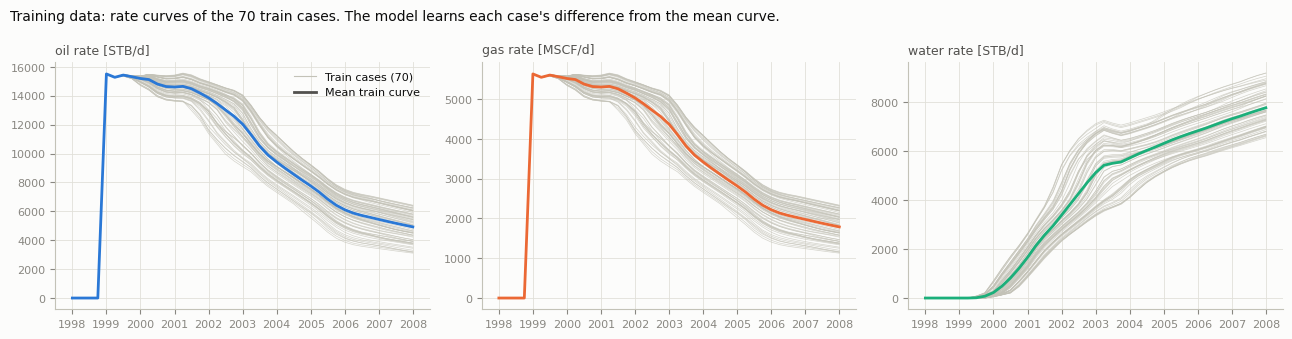

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
tr = splits == "train"
for j, ph in enumerate(pl.PHASES):
    ax = _ax(axes[j])
    for y in data_rate["Y"][tr, :, j]:
        ax.plot(dates, y, color=AXIS, lw=0.5, alpha=0.7)
    ax.plot(dates, data_rate["Y"][tr, :, j].mean(0), color=PH_COL[ph], lw=2)
    ax.set_title(f"{ph} rate [{UNITS[ph]}]", loc="left", fontsize=9, color=INK2)
axes[0].legend(handles=[Line2D([], [], color=AXIS, lw=0.8, label="Train cases (70)"),
                        Line2D([], [], color=INK2, lw=2, label="Mean train curve")], frameon=False, fontsize=8)
_finish(fig, "fig0_train_curves", "Training data: rate curves of the 70 train cases. The model learns each case's difference from the mean curve.")

## 2. Features

* **`p4`**: the 4 uncertainty parameters, min-max scaled with the train cases.
* **`p4g8`**: plus 8 grid summaries per case (from the grid files 03-08, notebook 1): total, aquifer and reservoir pore volume, mean porosity, mean permeability (all cells and in the permeability zone), mean transmissibility in x and y. Standardised with the train cases.

The grid of every case is case 1 scaled by the parameter ratios (notebook 1, section 5.1). So the 8 features are functions of the parameters. To predict for a **new** parameter set (history matching), the features must be computed from the parameters. Elton's `GridMapper` does this: analytic scaling, or, if any feature misses the stored values by 0.2 train standard deviations or more, a linear fit on `[1, r_poro, r_perm, r_poro x r_aq]` on the 70 train cases, checked on the 30 others.

In [5]:
print(data_rate["grid"].assign(case_id=case_ids, split=splits).head(5).round(3).to_string(index=False))
MAPPER = pl.GridMapper(data_rate)
print(f"\nGrid mapper method: {MAPPER.method}")
print("Errors in train standard deviations (tolerance 0.2):")
print(MAPPER.report.round(4).to_string())

    total_pv  aquifer_pv_grid  reservoir_pv  mean_poro  mean_permx  mean_permx_zone  mean_tranx  mean_trany  case_id split
4.251301e+09     3.548713e+09  7.025873e+08      0.117      72.846            0.595       1.615       1.581        1 train
7.874391e+09     7.076323e+09  7.980679e+08      0.133      73.022            1.241       1.619       1.584        2 train
9.028872e+09     8.453861e+09  5.750108e+08      0.096      72.763            0.289       1.612       1.579        3 train
1.123162e+10     1.034608e+10  8.855384e+08      0.148      73.142            1.680       1.622       1.587        4 train
6.816995e+09     6.200684e+09  6.163109e+08      0.103      72.971            1.054       1.618       1.583        5 train

Grid mapper method: fallback
Errors in train standard deviations (tolerance 0.2):
                 analytic_max_error_sigma  fallback_max_error_train_sigma  fallback_max_error_holdout_sigma
feature                                                                

**Reading.** The analytic scaling is exact for 6 features but misses `mean_tranx` by 0.29 sd (transmissibility is not a simple product of the zone permeability). So the mapper falls back to the linear fit, which reproduces all 8 features within 0.002 sd on the 30 held-out cases. Elton's pipeline made the same choice (same rule, same data).

## 3. Model

* **Residual learning.** The target is each case's curve minus the mean train curve, standardised per phase (`PhaseScaler`). Option `use_log`: a signed log of that residual.
* **Network.** An MLP with SiLU activations and dropout 0.05. Output: all 41 dates x 3 phases at once, so the curve shape is kept.
* **Training.** Full-batch Adam, cosine learning-rate decay, early stopping on the fold's validation cases (patience 300, at most 3,000 epochs).
* **Ensemble.** 5 networks from different seeds, averaged. Negative values are clipped to 0.

In [6]:
cfg_elton = pl.config_from_json(ELTON_OUT / "best_config.json")
in_dim = 4 + (8 if cfg_elton.feature_set == "p4g8" else 0)
net = pl.RateProxy(in_dim, pl.N_DATES * 3, cfg_elton.hidden, cfg_elton.dropout)
print(net)
print(f"weights per network: {sum(p.numel() for p in net.parameters()):,}   (Elton's best config: {cfg_elton})")

RateProxy(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=128, bias=True)
    (1): SiLU()
    (2): Dropout(p=0.05, inplace=False)
    (3): Linear(in_features=128, out_features=128, bias=True)
    (4): SiLU()
    (5): Dropout(p=0.05, inplace=False)
    (6): Linear(in_features=128, out_features=123, bias=True)
  )
)
weights per network: 34,043   (Elton's best config: Config(feature_set='p4g8', use_log=False, hidden=(128, 128), dropout=0.05, lr=0.001, weight_decay=0.0001, max_epochs=3000, patience=300))


## 4. Hyper-parameter tuning

Grid of 36 configurations: feature set (`p4`, `p4g8`) x target transform (plain, signed log) x width (32, 64, 128 per layer, 2 layers) x weight decay (1e-4, 1e-3, 1e-2).

1. **Stage 1:** all 36 on CV fold 0 (14 of the 70 train cases held out).
2. **Stage 2:** the best 3 on all 5 folds. The lowest mean RMSE wins.

Scores are RMSE of the rates (STB/d or MSCF/d, pooled over the phases). Every transform is fitted on the fold's training cases only.

In [7]:
if RUN_TUNE:
    torch.manual_seed(pl.SEED)
    CFG, TUNE_TABLE = pl.tune(data_rate)
    TUNE_TABLE.to_csv(PROXY_DIR / "config_search.csv", index=False)
else:
    CFG, TUNE_TABLE = cfg_elton, pd.read_csv(ELTON_OUT / "config_search.csv")
(PROXY_DIR / "best_config.json").write_text(json.dumps(pl.asdict(CFG) | {"hidden": list(CFG.hidden)}, indent=2))
print("\nChosen config:", CFG)

stage 1: 36 configs on fold(s) (0,)


  [ 1/36] p4 log=0 hidden=(32, 32) wd=0.0001 -> 57.1


  [ 2/36] p4 log=0 hidden=(32, 32) wd=0.001 -> 70.2


  [ 3/36] p4 log=0 hidden=(32, 32) wd=0.01 -> 117.7


  [ 4/36] p4 log=0 hidden=(64, 64) wd=0.0001 -> 55.2


...

  [35/36] p4g8 log=1 hidden=(128, 128) wd=0.001 -> 206.2


  [36/36] p4g8 log=1 hidden=(128, 128) wd=0.01 -> 962.1
stage 2: top 3 on all 5 folds


  p4g8 log=0 hidden=(128, 128) wd=0.0001 -> 36.3  epochs=[2613, 1542, 2524, 2255, 1936]


  p4g8 log=0 hidden=(64, 64) wd=0.0001 -> 40.6  epochs=[2612, 2466, 2522, 2547, 2288]


  p4g8 log=0 hidden=(32, 32) wd=0.0001 -> 48.9  epochs=[2562, 847, 1955, 2570, 1218]
tuning done in 250 s

Chosen config: Config(feature_set='p4g8', use_log=False, hidden=(128, 128), dropout=0.05, lr=0.001, weight_decay=0.0001, max_epochs=3000, patience=300)


In [8]:
# Compare with Elton's search: same grid, same folds, same seeds -> the same choice is expected.
key = ["feature_set", "use_log", "hidden", "weight_decay"]
el = pd.read_csv(ELTON_OUT / "config_search.csv")
ours = TUNE_TABLE.assign(stage=np.where(TUNE_TABLE["rmse_fold1"].notna(), "5 folds", "fold 0"))
cmp_ = ours[key + ["stage", "mean_val_rmse"]].merge(el[key + ["mean_val_rmse"]], on=key, suffixes=("_ours", "_elton"))
print("Best 8 configurations (RMSE, rate units):")
print(cmp_.sort_values("mean_val_rmse_ours").head(8).to_string(index=False, float_format=lambda v: f"{v:.4g}"))
same = pl.asdict(CFG) == pl.asdict(cfg_elton)
print(f"\nSame best config as Elton: {same}.  Largest RMSE difference to Elton's table: "
      f"{(cmp_['mean_val_rmse_ours'] - cmp_['mean_val_rmse_elton']).abs().max():.3f}")

Best 8 configurations (RMSE, rate units):
feature_set  use_log  hidden  weight_decay   stage  mean_val_rmse_ours  mean_val_rmse_elton
       p4g8    False 128x128        0.0001 5 folds               36.27                36.27
       p4g8    False   64x64        0.0001 5 folds               40.57                40.57
       p4g8    False   32x32        0.0001 5 folds               48.85                48.85
       p4g8    False   64x64         0.001  fold 0               54.38                54.38
       p4g8    False 128x128         0.001  fold 0               54.55                54.55
         p4    False 128x128        0.0001  fold 0               54.95                54.95
         p4    False   64x64        0.0001  fold 0               55.22                55.22
       p4g8    False   32x32         0.001  fold 0               55.26                55.26

Same best config as Elton: True.  Largest RMSE difference to Elton's table: 0.002


## 5. Rate proxy: final ensemble

The final ensemble is trained on all 70 train cases for a fixed number of epochs: the median early-stopping epoch of the 5 CV folds. Two baselines use the same inputs:

* **ridge**: linear regression from the inputs to the 123 outputs (alpha by 5-fold CV);
* **mean curve**: the mean train curve for every case.

In [9]:
t0 = time.time()
torch.manual_seed(pl.SEED); np.random.seed(pl.SEED)
STATES_R, SCALER_R, EPOCHS_R = pl.train_final(data_rate, CFG, n_seeds=N_SEEDS)
X_R = pl.build_inputs(data_rate, CFG.feature_set)
PRED_R = pl.predict_ensemble(STATES_R, SCALER_R, X_R, CFG)
RIDGE_R = pl.baseline_ridge(data_rate, CFG)
MEAN_R = pl.baseline_mean_curve(data_rate)
rows = []
for sp in ["train", "validation", "test"]:
    m = splits == sp
    for nm, p in [("dnn_ensemble", PRED_R), ("ridge", RIDGE_R), ("mean_curve", MEAN_R)]:
        rows += pl.metrics_table(data_rate["Y"], p, m, sp, nm)
METRICS_R = pd.DataFrame(rows)
METRICS_R.to_csv(PROXY_DIR / "metrics_rate.csv", index=False)
pl.save_checkpoint(PROXY_DIR / "final_model.pt", CFG, STATES_R, SCALER_R, data_rate, EPOCHS_R, N_SEEDS, MAPPER)
print(f"trained in {time.time() - t0:.0f} s")
piv = METRICS_R.pivot_table(index=["split", "phase"], columns="model", values="rmse").reindex(
    columns=["dnn_ensemble", "ridge", "mean_curve"])
print("\nRMSE (STB/d for oil and water, MSCF/d for gas):")
print(piv.loc[["train", "validation", "test"]].round(1).to_string())

final epochs from CV median: 2255


  ensemble member 1/5 trained (2255 epochs)


  ensemble member 2/5 trained (2255 epochs)


  ensemble member 3/5 trained (2255 epochs)


  ensemble member 4/5 trained (2255 epochs)


  ensemble member 5/5 trained (2255 epochs)


ridge: alpha=0.1 (CV RMSE 120.2)
trained in 51 s

RMSE (STB/d for oil and water, MSCF/d for gas):
model             dnn_ensemble  ridge  mean_curve
split      phase                                 
train      all            28.3  110.9       685.5
           gas            11.6   52.8       324.1
           oil            34.8  147.1       892.5
           water          32.5  111.8       713.0
validation all            32.7  127.6       719.9
           gas            14.1   63.4       338.3
           oil            42.1  174.9       932.4
           water          35.3  119.3       755.5
test       all            32.5  135.8       763.5
           gas            13.9   68.4       369.0
           oil            41.2  190.8      1015.9
           water          35.7  119.5       762.1


In [10]:
el_m = pd.read_csv(ELTON_OUT / "metrics.csv")
c = METRICS_R[(METRICS_R.model == "dnn_ensemble")].merge(
    el_m[el_m.model == "dnn_ensemble"], on=["split", "model", "phase"], suffixes=("_ours", "_elton"))
print("Rate proxy, ours against Elton's saved run (RMSE):")
print(c.pivot_table(index="phase", columns="split", values=["rmse_ours", "rmse_elton"]).round(1).to_string())

Rate proxy, ours against Elton's saved run (RMSE):
      rmse_elton                  rmse_ours                 
split       test train validation      test train validation
phase                                                       
all         32.5  28.3       32.7      32.5  28.3       32.7
gas         13.9  11.6       14.1      13.9  11.6       14.1
oil         41.2  34.8       42.1      41.2  34.8       42.1
water       35.7  32.5       35.3      35.7  32.5       35.3


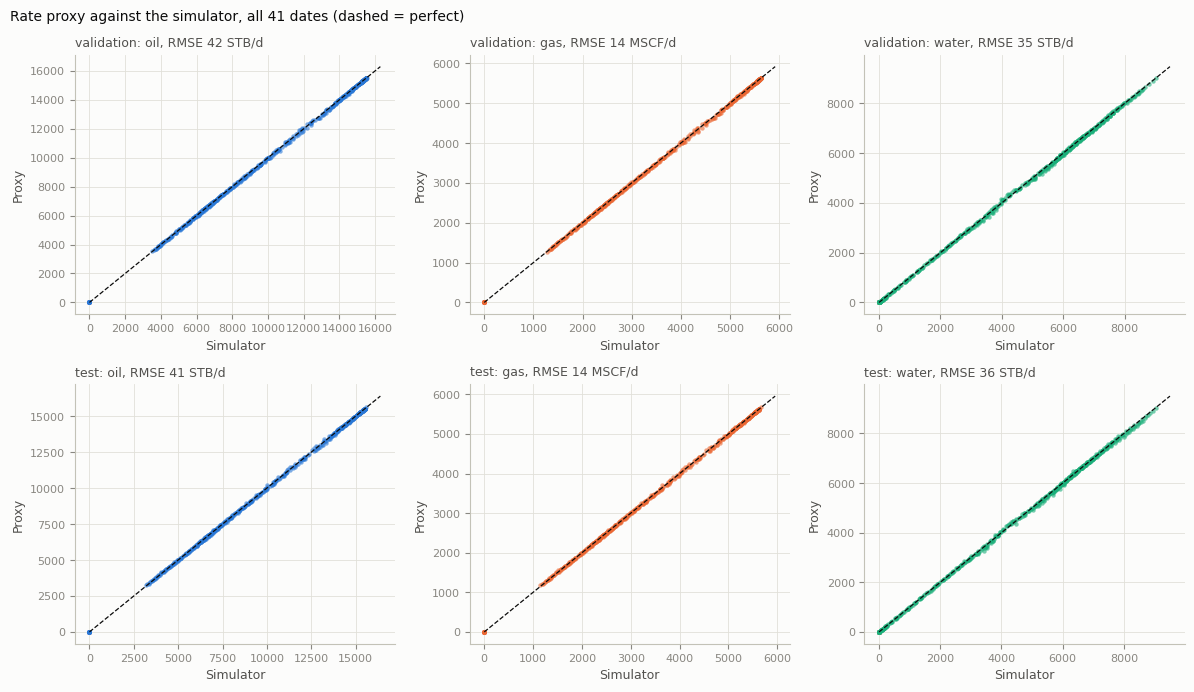

In [11]:
# Fig 1: proxy against simulator, validation and test
fig, ax = plt.subplots(2, 3, figsize=(12, 7))
for r, sp in enumerate(["validation", "test"]):
    m = splits == sp
    for j, ph in enumerate(pl.PHASES):
        a = _ax(ax[r, j])
        t, p = data_rate["Y"][m][:, :, j].ravel(), PRED_R[m][:, :, j].ravel()
        a.scatter(t, p, s=10, alpha=0.6, color=PH_COL[ph], linewidths=0)
        lim = [0, max(t.max(), p.max()) * 1.05]
        a.plot(lim, lim, color=INK, lw=0.9, ls="--")
        a.set_title(f"{sp}: {ph}, RMSE {np.sqrt(np.mean((t - p) ** 2)):,.0f} {UNITS[ph]}", loc="left", fontsize=9, color=INK2)
        a.set_xlabel("Simulator"); a.set_ylabel("Proxy")
_finish(fig, "fig1_pred_vs_truth", "Rate proxy against the simulator, all 41 dates (dashed = perfect)")

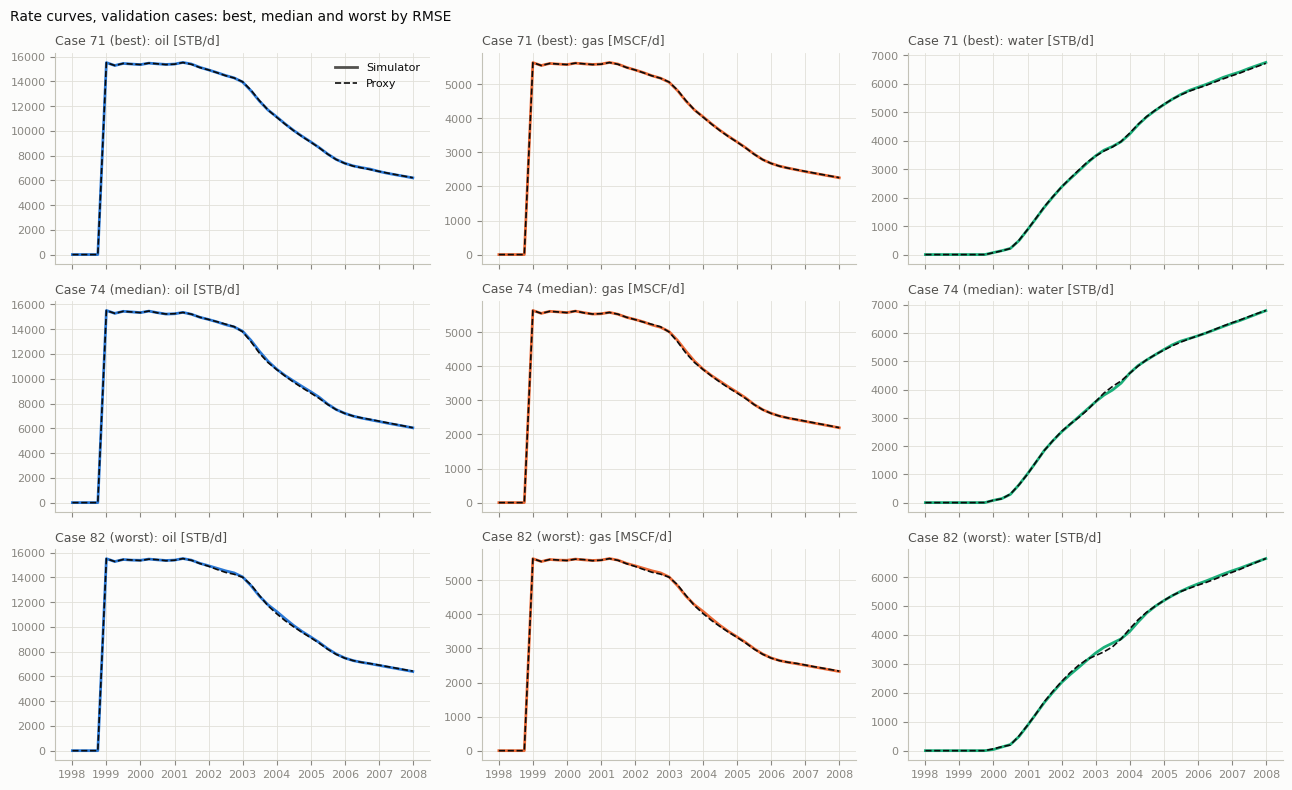

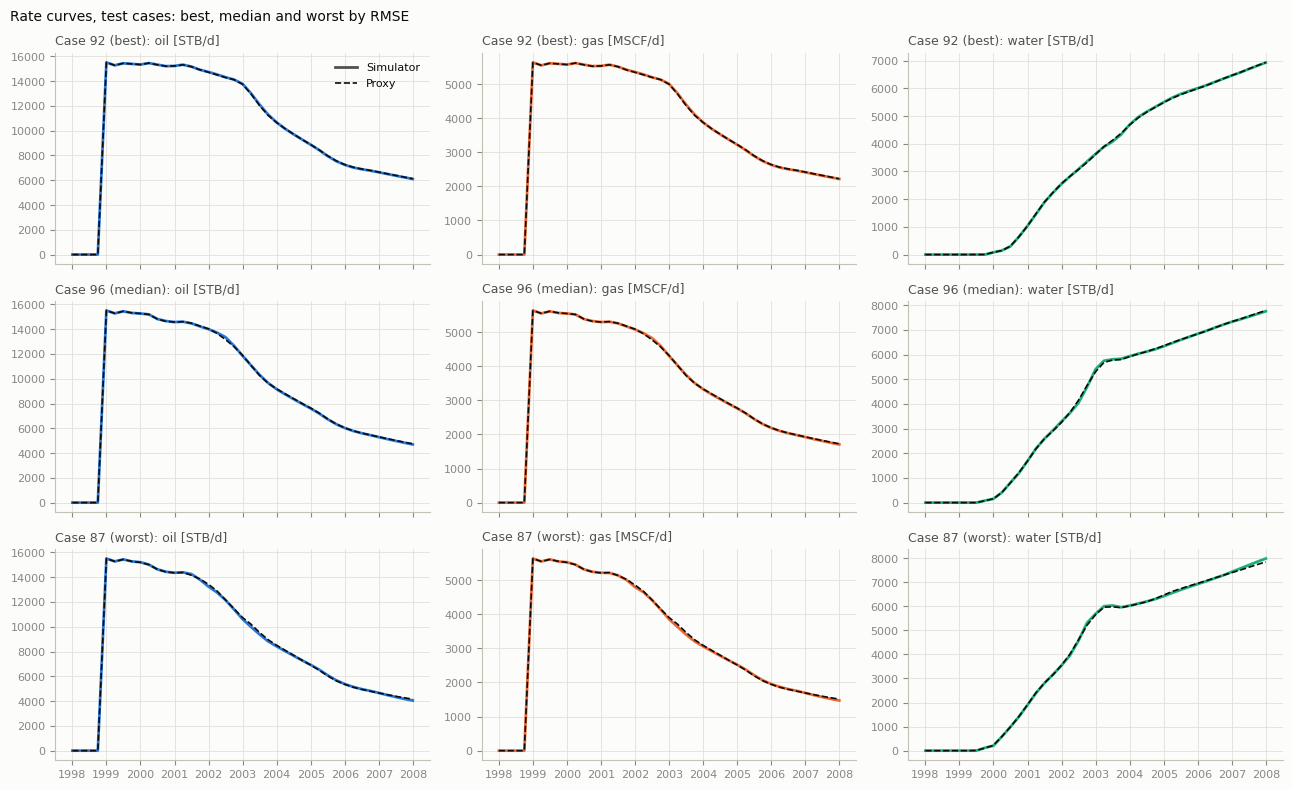

worst validation cases: [(82, 45.28973204250769), (76, 41.68600273994331), (80, 37.78115169594118)]
worst test cases: [(87, 51.02205300023439), (98, 43.24987175184427), (95, 39.97653797570768)]


In [12]:
# Fig 2: best / median / worst case of validation and test
for sp in ["validation", "test"]:
    ids = case_ids[splits == sp]
    rm = np.sqrt(np.mean((data_rate["Y"] - PRED_R) ** 2, axis=(1, 2)))
    ranked = sorted(ids, key=lambda c: rm[c - 1])
    show = [ranked[0], ranked[len(ranked) // 2], ranked[-1]]
    fig, axes = plt.subplots(3, 3, figsize=(13, 8), sharex=True)
    for r, (cid, lab) in enumerate(zip(show, ["best", "median", "worst"])):
        for j, ph in enumerate(pl.PHASES):
            a = _ax(axes[r, j])
            a.plot(dates, data_rate["Y"][cid - 1, :, j], color=PH_COL[ph], lw=2)
            a.plot(dates, PRED_R[cid - 1, :, j], color=INK, lw=1.2, ls="--")
            a.set_title(f"Case {cid} ({lab}): {ph} [{UNITS[ph]}]", loc="left", fontsize=9, color=INK2)
    axes[0, 0].legend(handles=[Line2D([], [], color=INK2, lw=2, label="Simulator"),
                               Line2D([], [], color=INK, lw=1.2, ls="--", label="Proxy")], frameon=False, fontsize=8)
    _finish(fig, f"fig2_curves_{sp}", f"Rate curves, {sp} cases: best, median and worst by RMSE")
print("worst validation cases:", pl.worst_cases(data_rate["Y"], PRED_R, splits == "validation", case_ids))
print("worst test cases:", pl.worst_cases(data_rate["Y"], PRED_R, splits == "test", case_ids))

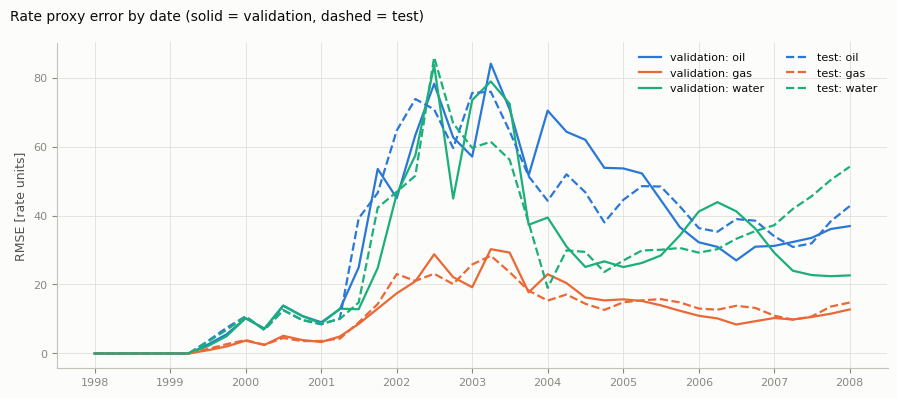

In [13]:
# Fig 3: error by date
fig, ax = plt.subplots(figsize=(9, 4))
_ax(ax)
for sp, ls in [("validation", "-"), ("test", "--")]:
    m = splits == sp
    for j, ph in enumerate(pl.PHASES):
        ax.plot(dates, np.sqrt(np.mean((data_rate["Y"][m][:, :, j] - PRED_R[m][:, :, j]) ** 2, axis=0)),
                ls, color=PH_COL[ph], lw=1.6, label=f"{sp}: {ph}")
ax.set_ylabel("RMSE [rate units]")
ax.legend(frameon=False, fontsize=8, ncol=2)
_finish(fig, "fig4_rmse_by_date", "Rate proxy error by date (solid = validation, dashed = test)")

**Reading (rate proxy).** The table above compares our run with Elton's saved run. The pooled test RMSE should sit near his 32.5 (oil 41, gas 14, water 36), about 4x better than ridge (136) and 20x better than the mean curve (764). The error is largest around the end of the oil plateau and at water breakthrough (2001-2003), where the curves of different cases separate.

## 6. Cumulative twin proxy (used by the history matching)

Elton trains a twin of the rate proxy on cumulative curves, with the **same configuration** and protocol. It ships only if it beats the ridge baseline on the test cases (his gate).

**Check (improvised).** The configuration was tuned on rates. Before reusing it, the best 3 configurations of the search are re-run with 5-fold CV on the cumulative target. This is a check only: Elton's choice is kept unless it is clearly beaten.

In [14]:
t0 = time.time()
top3 = TUNE_TABLE.dropna(subset=["rmse_fold1"]).sort_values("mean_val_rmse").head(3)
rows = []
for _, r in top3.iterrows():
    c3 = pl.row_cfg(r)
    res = pl.run_config(data_cum, c3, folds={0, 1, 2, 3, 4})
    rows.append({**pl.cfg_row(c3), "cv_rmse_cumulative": res["val_rmse"], "cv_rmse_rate": r["mean_val_rmse"]})
CUM_CHECK = pd.DataFrame(rows)
CUM_CHECK["cv_rmse_cumulative_%_of_final_oil"] = CUM_CHECK["cv_rmse_cumulative"] / data_cum["y_hist"][-1, 0] * 100
CUM_CHECK.to_csv(PROXY_DIR / "config_check_cumulative.csv", index=False)
print(f"{time.time() - t0:.0f} s. 5-fold CV RMSE on the cumulative target (STB / MSCF, pooled):")
print(CUM_CHECK.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
best_c = CUM_CHECK.sort_values("cv_rmse_cumulative").iloc[0]
chosen_row = CUM_CHECK[(CUM_CHECK.feature_set == CFG.feature_set) & (CUM_CHECK.hidden == "x".join(map(str, CFG.hidden)))
                       & (CUM_CHECK.weight_decay == CFG.weight_decay) & (CUM_CHECK.use_log == CFG.use_log)]
gap = float(chosen_row["cv_rmse_cumulative"].iloc[0] / best_c["cv_rmse_cumulative"] - 1) if len(chosen_row) else np.nan
print(f"\nThe chosen config is {gap:.1%} above the best of the three on cumulatives -> "
      + ("keep it (within 10%)." if gap <= 0.10 else "NOTE: another config is clearly better on cumulatives."))

38 s. 5-fold CV RMSE on the cumulative target (STB / MSCF, pooled):
feature_set  use_log  hidden  dropout    lr  weight_decay  cv_rmse_cumulative  cv_rmse_rate  cv_rmse_cumulative_%_of_final_oil
       p4g8    False 128x128     0.05 0.001        0.0001           2.236e+04         36.27                            0.05826
       p4g8    False   64x64     0.05 0.001        0.0001           2.353e+04         40.57                            0.06131
       p4g8    False   32x32     0.05 0.001        0.0001           3.196e+04         48.85                            0.08327

The chosen config is 0.0% above the best of the three on cumulatives -> keep it (within 10%).


In [15]:
t0 = time.time()
torch.manual_seed(pl.SEED); np.random.seed(pl.SEED)
STATES_C, SCALER_C, EPOCHS_C = pl.train_final(data_cum, CFG, n_seeds=N_SEEDS)
X_C = pl.build_inputs(data_cum, CFG.feature_set)
PRED_C = pl.predict_ensemble(STATES_C, SCALER_C, X_C, CFG)
RIDGE_C = pl.baseline_ridge(data_cum, CFG)
MEAN_C = pl.baseline_mean_curve(data_cum)
rows = []
for sp in ["train", "validation", "test"]:
    m = splits == sp
    for nm, p in [("dnn_ensemble", PRED_C), ("ridge", RIDGE_C), ("mean_curve", MEAN_C)]:
        rows += pl.metrics_table(data_cum["Y"], p, m, sp, nm)
METRICS_C = pd.DataFrame(rows)
METRICS_C.to_csv(PROXY_DIR / "metrics_cumulative.csv", index=False)
t_ = METRICS_C[(METRICS_C.split == "test") & (METRICS_C.phase == "all")].set_index("model")["rmse"]
GATE_OK = bool(t_["dnn_ensemble"] < t_["ridge"])
print(f"trained in {time.time() - t0:.0f} s. Gate (test RMSE below ridge): {'PASS' if GATE_OK else 'FAIL'} "
      f"({t_['dnn_ensemble']:,.0f} vs {t_['ridge']:,.0f})")
assert GATE_OK, "cumulative proxy does not beat ridge on the test cases - do not ship it"
pl.save_checkpoint(PROXY_DIR / "cumulative_model.pt", CFG, STATES_C, SCALER_C, data_cum, EPOCHS_C, N_SEEDS, MAPPER)
piv = METRICS_C.pivot_table(index=["split", "phase"], columns="model", values="rmse").reindex(
    columns=["dnn_ensemble", "ridge", "mean_curve"])
print("\nRMSE of the cumulative curves (STB for oil and water, MSCF for gas):")
print(piv.loc[["train", "validation", "test"]].round(0).to_string())
el_c = pd.read_csv(ELTON_OUT / "cumulative_metrics.csv")
cc = METRICS_C[METRICS_C.model == "dnn_ensemble"].merge(el_c[el_c.model == "dnn_ensemble"], on=["split", "model", "phase"],
                                                          suffixes=("_ours", "_elton"))
print("\nOurs against Elton's saved cumulative run (RMSE):")
print(cc.pivot_table(index="phase", columns="split", values=["rmse_ours", "rmse_elton"]).round(0).to_string())

final epochs from CV median: 743


  ensemble member 1/5 trained (743 epochs)


  ensemble member 2/5 trained (743 epochs)


  ensemble member 3/5 trained (743 epochs)


  ensemble member 4/5 trained (743 epochs)


  ensemble member 5/5 trained (743 epochs)
ridge: alpha=0.1 (CV RMSE 155,159.7)
trained in 19 s. Gate (test RMSE below ridge): PASS (23,097 vs 181,002)

RMSE of the cumulative curves (STB for oil and water, MSCF for gas):
model             dnn_ensemble     ridge  mean_curve
split      phase                                    
train      all         21898.0  143096.0   1101121.0
           gas          8545.0   73783.0    512932.0
           oil         24222.0  204233.0   1410887.0
           water       27909.0  119477.0   1176309.0
validation all         21723.0  166057.0   1158406.0
           gas          9370.0   88089.0    536379.0
           oil         27440.0  242364.0   1475768.0
           water       23977.0  127377.0   1249048.0
test       all         23097.0  181002.0   1217280.0
           gas          8864.0   98531.0    578543.0
           oil         25915.0  272330.0   1590414.0
           water       29161.0  120054.0   1257452.0

Ours against Elton's saved cumulati

## 7. Accuracy in history-matching units

The history matching (notebook 3) does not care about RMSE in barrels. It compares curves with the observed history as a **share of the final observed cumulative** (2008-01-01), over the **37 producing quarters** (1999-01-01 to 2008-01-01), for oil and water. Gas is about 0.3633 x oil in every case, so it adds no information. This section measures the proxy in exactly those units.

* The proxy is called the way notebook 3 calls it: from raw parameters, with the grid features from the mapper (not the stored ones).
* **`sigma_proxy`** (passed to notebook 3) = RMS relative error over the **validation** cases and the 37 dates, per phase. The test cases are reported, not used.
* **Ranking check:** the history-matching score of each case, computed once from the proxy curves and once from the simulator curves. If the proxy ranks the validation and test cases in the same order as the simulator (Spearman near 1), it can be trusted to find good matches.

In [16]:
CKPT_C = pl.load_checkpoint(PROXY_DIR / "cumulative_model.pt")
THETA = cases[pl.PARAMS].to_numpy(float)
PRED_HM = pl.predict_from_params(CKPT_C, THETA)                  # (100, 41, 3) oil, gas, water - the notebook-3 path
Y_C, Y_H = data_cum["Y"], data_cum["y_hist"]
FINAL = Y_H[-1]                                                  # observed cumulative at 2008-01-01
WIN = np.where(Y_H[:, 0] > 0)[0]                                 # producing quarters
print(f"matching window: {dates[WIN[0]].date()} to {dates[WIN[-1]].date()} ({len(WIN)} dates)")
print(f"mapper path against stored-grid path, max difference: "
      f"{(np.abs(PRED_HM - PRED_C) / FINAL).max() * 100:.4f} % of the final observed value")

REL = (PRED_HM - Y_C)[:, WIN] / FINAL                            # (100, 37, 3) relative error
rows = []
for sp in ["train", "validation", "test"]:
    m = splits == sp
    r = {"split": sp}
    for j, ph in enumerate(pl.PHASES):
        r[f"rms_{ph}_%"] = np.sqrt((REL[m][:, :, j] ** 2).mean()) * 100
        r[f"max_{ph}_%"] = np.abs(REL[m][:, :, j]).max() * 100
    rows.append(r)
ACC_HM = pd.DataFrame(rows).set_index("split")
ACC_HM.to_csv(PROXY_DIR / "accuracy_hm_units.csv")
print("\nCumulative error of the proxy, % of the final observed cumulative, 37-date window:")
print(ACC_HM.round(3).to_string())

val = splits == "validation"
SIGMA_PROXY = {f"{ph}_cum": float(np.sqrt((REL[val][:, :, j] ** 2).mean())) for j, ph in enumerate(pl.PHASES)}
SIGMA_PROXY_TEST = {f"{ph}_cum": float(np.sqrt((REL[splits == 'test'][:, :, j] ** 2).mean())) for j, ph in enumerate(pl.PHASES)}
ERR_BY_DATE = pd.DataFrame({"date": dates[WIN].strftime("%Y-%m-%d"),
                            **{f"{ph}_cum": np.sqrt((REL[val][:, :, j] ** 2).mean(axis=0)) for j, ph in enumerate(pl.PHASES)}})
print("\nsigma_proxy passed to notebook 3 (share of final, validation):", {k: round(v, 5) for k, v in SIGMA_PROXY.items()})

matching window: 1999-01-01 to 2008-01-01 (37 dates)
mapper path against stored-grid path, max difference: 0.0008 % of the final observed value

Cumulative error of the proxy, % of the final observed cumulative, 37-date window:
            rms_oil_%  max_oil_%  rms_gas_%  max_gas_%  rms_water_%  max_water_%
split                                                                           
train           0.066      0.348      0.065      0.367        0.229        1.685
validation      0.075      0.233      0.071      0.204        0.197        0.780
test            0.071      0.303      0.067      0.273        0.240        0.881

sigma_proxy passed to notebook 3 (share of final, validation): {'oil_cum': 0.00075, 'gas_cum': 0.00071, 'water_cum': 0.00197}


In [17]:
def hm_score(C):
    # Notebook-3 headline score: sqrt(mean over oil and water of the squared NRMSE on the window).
    R = (C[:, WIN][:, :, [0, 2]] - Y_H[WIN][:, [0, 2]]) / FINAL[[0, 2]]
    return np.sqrt((R ** 2).mean(axis=1).mean(axis=1))


S_SIM, S_PROXY = hm_score(Y_C), hm_score(PRED_HM)
RANK = pd.DataFrame({"case_id": case_ids, "split": splits, "score_simulator": S_SIM, "score_proxy": S_PROXY})
RANK["abs_diff"] = (RANK.score_proxy - RANK.score_simulator).abs()
RANK.to_csv(PROXY_DIR / "hm_score_proxy_vs_simulator.csv", index=False)
rows = []
for sp in ["train", "validation", "test"]:
    s = RANK[RANK.split == sp]
    rows.append({"split": sp, "spearman": spearmanr(s.score_simulator, s.score_proxy)[0],
                 "mean_abs_diff_%": s.abs_diff.mean() * 100, "max_abs_diff_%": s.abs_diff.max() * 100})
print("History-matching score from proxy curves against simulator curves:")
print(pd.DataFrame(rows).round(4).to_string(index=False))
near = RANK.sort_values("score_simulator").head(10)
print("\nThe 10 cases closest to the history (simulator score), all splits:")
print((near.set_index("case_id")[["split", "score_simulator", "score_proxy", "abs_diff"]]
       .assign(**{c: lambda d, c=c: d[c] * 100 for c in ["score_simulator", "score_proxy", "abs_diff"]})
       .round(3).rename(columns=lambda c: c + ("_%" if c != "split" else ""))).to_string())

History-matching score from proxy curves against simulator curves:
     split  spearman  mean_abs_diff_%  max_abs_diff_%
     train    0.9988           0.0925          0.4746
validation    1.0000           0.0920          0.2091
      test    1.0000           0.1106          0.2298

The 10 cases closest to the history (simulator score), all splits:
              split  score_simulator_%  score_proxy_%  abs_diff_%
case_id                                                          
6             train              0.494          0.533       0.039
97             test              0.522          0.546       0.024
76       validation              0.528          0.510       0.017
11            train              0.533          0.480       0.053
40            train              0.537          0.526       0.011
73       validation              0.544          0.592       0.049
50            train              0.609          0.524       0.085
20            train              0.682          0.652  

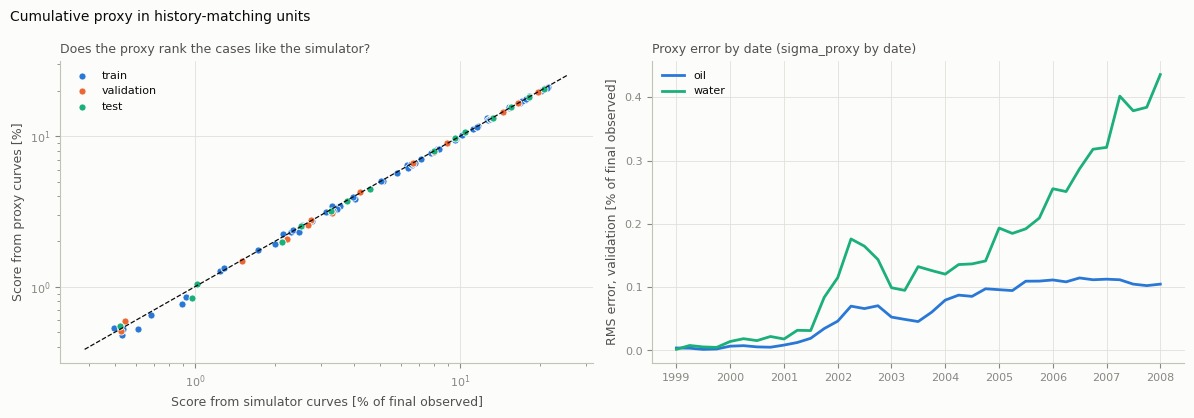

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = _ax(axes[0])
for sp in ["train", "validation", "test"]:
    s = RANK[RANK.split == sp]
    ax.scatter(s.score_simulator * 100, s.score_proxy * 100, s=26, color=SPLIT_COL[sp], label=sp,
               edgecolors=SURF, linewidths=0.6)
lim = [RANK[["score_simulator", "score_proxy"]].min().min() * 80, RANK[["score_simulator", "score_proxy"]].max().max() * 120]
ax.plot(lim, lim, color=INK, lw=0.9, ls="--")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Score from simulator curves [% of final observed]"); ax.set_ylabel("Score from proxy curves [%]")
ax.legend(frameon=False, fontsize=8)
ax.set_title("Does the proxy rank the cases like the simulator?", loc="left", fontsize=9, color=INK2)
ax = _ax(axes[1])
for ph in ["oil", "water"]:
    ax.plot(dates[WIN], ERR_BY_DATE[f"{ph}_cum"] * 100, color=PH_COL[ph], lw=2, label=f"{ph}")
ax.set_ylabel("RMS error, validation [% of final observed]")
ax.legend(frameon=False, fontsize=8)
ax.set_title("Proxy error by date (sigma_proxy by date)", loc="left", fontsize=9, color=INK2)
_finish(fig, "fig5_hm_units", "Cumulative proxy in history-matching units")

## 8. Export to `hist_match_input/`

Notebook 3 needs two kinds of input:

1. **Curves of the known cases**, to score them against the history (method A): the simulator curves (exact) and, for checks, the proxy curves of the same cases.
2. **The proxy itself**, to evaluate parameter sets that are not among the 100 cases (MCMC, direct sampling, implausibility, search), with its error `sigma_proxy`.

| File | Content |
|---|---|
| `simulated.csv` | Long format: `case_id, split, date, gas_cum, oil_cum, water_cum`. The simulator curves of the 100 cases (41 dates) |
| `predictions.csv` | Same layout: the proxy's curves of the same 100 cases (through the grid mapper, as notebook 3 calls it) |
| `case_params.csv` | `case_id, split`, the 4 parameters (real units) |
| `cumulative_model.pt` | The trained cumulative proxy (5 networks, scaler, grid mapper, train bounds) |
| `proxy_meta.json` | Model hash (sha256), config, train bounds, `sigma_proxy` (validation; test for reference), window, phase order |
| `proxy_error_by_date.csv` | Validation RMS error per window date and phase, share of the final observed value |

Notebook 3 loads the proxy with `proxy_lib.CumulativeProxy("hist_match_input/", window_dates)`. It stops if the model file does not match the hash in `proxy_meta.json`.

In [19]:
def long_table(C):
    rows = []
    for i, cid in enumerate(case_ids):
        d = pd.DataFrame({"case_id": cid, "split": splits[i], "date": dates.strftime("%Y-%m-%d")})
        for j, ph in enumerate(pl.PHASES):
            d[f"{ph}_cum"] = C[i, :, j]
        rows.append(d[["case_id", "split", "date", "gas_cum", "oil_cum", "water_cum"]])
    return pd.concat(rows, ignore_index=True)


long_table(Y_C).to_csv(HM_IN / "simulated.csv", index=False)
long_table(PRED_HM).to_csv(HM_IN / "predictions.csv", index=False)
cases[["case_id", "split"] + pl.PARAMS].to_csv(HM_IN / "case_params.csv", index=False)
ERR_BY_DATE.to_csv(HM_IN / "proxy_error_by_date.csv", index=False)
shutil.copy2(PROXY_DIR / "cumulative_model.pt", HM_IN / "cumulative_model.pt")

tr = splits == "train"
META = {
    "model_file": "cumulative_model.pt",
    "model_sha256": pl.sha256(HM_IN / "cumulative_model.pt"),
    "made_by": "notebook2_proxy_model.ipynb",
    "created": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"),
    "target": "cumulative production, real units (STB oil and water, MSCF gas)",
    "phase_order_in_model": pl.PHASES,
    "config": pl.asdict(CFG) | {"hidden": list(CFG.hidden)},
    "epochs": int(EPOCHS_C), "n_seeds": N_SEEDS,
    "grid_mapper": MAPPER.method,
    "train_min": {p: float(v) for p, v in zip(pl.PARAMS, THETA[tr].min(0))},
    "train_max": {p: float(v) for p, v in zip(pl.PARAMS, THETA[tr].max(0))},
    "window": {"start": str(dates[WIN[0]].date()), "end": str(dates[WIN[-1]].date()), "n_dates": int(len(WIN))},
    "observed_final": {f"{ph}_cum": float(FINAL[j]) for j, ph in enumerate(pl.PHASES)},
    "sigma_proxy": SIGMA_PROXY,
    "sigma_proxy_test": SIGMA_PROXY_TEST,
    "sigma_proxy_note": "RMS of (proxy - simulator) / observed final cumulative, window dates, validation cases 71-85",
    "rate_proxy_test_rmse_pooled": float(METRICS_R.query("split=='test' and model=='dnn_ensemble' and phase=='all'")["rmse"].iloc[0]),
}
(HM_IN / "proxy_meta.json").write_text(json.dumps(META, indent=2))

# round trip: load it the way notebook 3 does and compare with the curves above
_p = pl.CumulativeProxy(HM_IN, dates[WIN].values, ("oil_cum", "water_cum"))
assert np.allclose(_p(THETA), PRED_HM[:, WIN][:, :, [0, 2]])
print("exported to", HM_IN)
for f in sorted(HM_IN.iterdir()):
    print(f"  {f.name:<26} {f.stat().st_size / 1e3:>9.1f} kB")
print("round trip through CumulativeProxy: OK")

exported to C:\Users\Yi Siang\Documents\UM\dwc_team_what_repo\hist_match_input
  case_params.csv                  8.0 kB
  cumulative_model.pt            700.5 kB
  predictions.csv                305.0 kB
  proxy_error_by_date.csv          2.9 kB
  proxy_meta.json                  1.7 kB
  README.md                        2.9 kB
  simulated.csv                  212.9 kB
round trip through CumulativeProxy: OK


## 9. Summary

In [20]:
mr = METRICS_R.query("model=='dnn_ensemble' and phase=='all'").set_index("split")["rmse"]
rr = METRICS_R.query("model=='ridge' and phase=='all'").set_index("split")["rmse"]
summary = {
    "best_config": pl.asdict(CFG) | {"hidden": list(CFG.hidden)},
    "same_config_as_elton": bool(pl.asdict(CFG) == pl.asdict(cfg_elton)),
    "rate_proxy_rmse_pooled": {k: round(float(v), 2) for k, v in mr.items()},
    "rate_ridge_rmse_pooled": {k: round(float(v), 2) for k, v in rr.items()},
    "epochs_rate": int(EPOCHS_R), "epochs_cumulative": int(EPOCHS_C),
    "cumulative_gate_pass": GATE_OK,
    "hm_units_rms_%": ACC_HM.round(4).to_dict(orient="index"),
    "sigma_proxy": SIGMA_PROXY,
    "score_spearman": {sp: round(float(spearmanr(RANK[RANK.split == sp].score_simulator,
                                                 RANK[RANK.split == sp].score_proxy)[0]), 4)
                       for sp in ["train", "validation", "test"]},
    "grid_mapper": MAPPER.method,
}
(PROXY_DIR / "proxy_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "best_config": {
    "feature_set": "p4g8",
    "use_log": false,
    "hidden": [
      128,
      128
    ],
    "dropout": 0.05,
    "lr": 0.001,
    "weight_decay": 0.0001,
    "max_epochs": 3000,
    "patience": 300
  },
  "same_config_as_elton": true,
  "rate_proxy_rmse_pooled": {
    "train": 28.27,
    "validation": 32.72,
    "test": 32.47
  },
  "rate_ridge_rmse_pooled": {
    "train": 110.95,
    "validation": 127.59,
    "test": 135.85
  },
  "epochs_rate": 2255,
  "epochs_cumulative": 743,
  "cumulative_gate_pass": true,
  "hm_units_rms_%": {
    "train": {
      "rms_oil_%": 0.0665,
      "max_oil_%": 0.3484,
      "rms_gas_%": 0.0645,
      "max_gas_%": 0.3669,
      "rms_water_%": 0.2293,
      "max_water_%": 1.685
    },
    "validation": {
      "rms_oil_%": 0.0753,
      "max_oil_%": 0.2329,
      "rms_gas_%": 0.0708,
      "max_gas_%": 0.2044,
      "rms_water_%": 0.197,
      "max_water_%": 0.7801
    },
    "test": {
      "rms_oil_%": 0.0711,
      "max_oil_%"

**How to read it.**

* **Reproduction.** Same tuning grid, folds and seeds as Elton. The chosen configuration and the error figures are compared with his saved run in sections 4-6.
* **Rate proxy.** About 4x better than ridge on the test cases. This is Elton's step-1 result.
* **Cumulative proxy.** The error is a small fraction of a percent of the final observed cumulative (section 7), well below the mismatch of the best simulated case against the history (about 0.5 %, notebook 3). So the proxy is accurate enough to rank parameter sets against the history.
* **Limits.** The proxy is trained inside the train range of the parameters. A few validation and test cases lie slightly outside it (the worst cases above). Notebook 3 keeps its search inside the train range.
* **Next:** `notebook3_hist_match.ipynb` reads `hist_match_input/`.